In [1]:
from pathlib import Path
import json
import sqlite3
from html import escape
from IPython.display import HTML, SVG, display

from scraper.database import connect_database, initialize_database, rebuild_text_preparations
from scraper.text_analysis import run_text_analysis, latest_text_analysis
from scraper.text_classification import run_text_classification, latest_text_classification
from scraper.linguistic_analysis import run_linguistic_analysis, latest_linguistic_analysis
from scraper.text_embeddings import (
    contextualize_tokens,
    load_latest_embedding_model,
    run_embedding_analysis,
    latest_embedding_analysis,
    semantic_search,
)

def exibir_tabela(registros, colunas, mensagem_vazia="Nenhum registro encontrado."):
    registros = list(registros)
    estilo = (
        '<style>'
        'table.raspagem-table{border-collapse:collapse;width:100%;margin:0 0 16px;'
        'font:14px/1.4 system-ui,-apple-system,BlinkMacSystemFont,"Segoe UI",sans-serif}'
        '.raspagem-table th,.raspagem-table td{border:1px solid #d9dbe3;padding:8px 10px;'
        'text-align:left!important;vertical-align:top}'
        '.raspagem-table th{background:#f4f6fb;font-weight:600}'
        '</style>'
    )
    if not registros:
        display(HTML(estilo + f'<p>{escape(mensagem_vazia)}</p>'))
        return
    cabecalho = ''.join(f'<th>{escape(rotulo)}</th>' for chave, rotulo in colunas)
    linhas = []
    for registro in registros:
        celulas = ''.join(
            f'<td>{escape(str(registro.get(chave) if registro.get(chave) not in (None, "") else "—"))}</td>'
            for chave, rotulo in colunas
        )
        linhas.append(f'<tr>{celulas}</tr>')
    display(HTML(
        estilo
        + '<table class="raspagem-table"><thead><tr>'
        + cabecalho
        + '</tr></thead><tbody>'
        + ''.join(linhas)
        + '</tbody></table>'
    ))

DATABASE_PATH = Path("data/recipes.sqlite")
print("Banco configurado: data/recipes.sqlite")


Banco configurado: data/recipes.sqlite


In [2]:
connection = connect_database(DATABASE_PATH)
initialize_database(connection)
prepared_count = rebuild_text_preparations(connection)
analysis_run_id = run_text_analysis(connection, cluster_count=0, neighbor_count=5)
embedding_run_id = run_embedding_analysis(connection, dimension=32, window_size=2, neighbor_count=5)
try:
    classification_run_id = run_text_classification(connection, target_field="difficulty", test_ratio=0.25)
except ValueError as error:
    classification_run_id = None
    print(f"Classificação não gerada: {error}")
linguistic_run_id = run_linguistic_analysis(connection)
connection.close()

print(f"Preparação atualizada: {prepared_count} unidade(s)")
print(f"Análise TF-IDF gerada: execução {analysis_run_id}")
print(f"Embeddings gerados: execução {embedding_run_id}")
if classification_run_id is not None:
    print(f"Classificação gerada: execução {classification_run_id}")
print(f"Análise linguística gerada: execução {linguistic_run_id}")


Preparação atualizada: 2505 unidade(s)
Análise TF-IDF disponível: execução 4
Embeddings disponíveis: execução 3
Classificação disponível: execução 3
Análise linguística disponível: execução 3


## 1. Resumo do banco


In [3]:
connection = connect_database(DATABASE_PATH)
initialize_database(connection)
total_receitas = connection.execute("SELECT COUNT(*) FROM recipes").fetchone()[0]
custos_informados = connection.execute(
    "SELECT COUNT(*) FROM recipes WHERE NULLIF(TRIM(cost_label), '') IS NOT NULL"
).fetchone()[0]
receitas_com_categoria = connection.execute(
    "SELECT COUNT(DISTINCT recipe_id) FROM recipe_categories"
).fetchone()[0]
resumo = [
    {"metric": "Receitas", "value": total_receitas},
    {"metric": "Custos informados", "value": f"{custos_informados}/{total_receitas}"},
    {"metric": "Receitas com categoria", "value": f"{receitas_com_categoria}/{total_receitas}"},
    {"metric": "Ingredientes", "value": connection.execute("SELECT COUNT(*) FROM ingredients").fetchone()[0]},
    {"metric": "Passos de preparo", "value": connection.execute("SELECT COUNT(*) FROM preparation_steps").fetchone()[0]},
    {"metric": "Categorias", "value": connection.execute("SELECT COUNT(*) FROM categories").fetchone()[0]},
    {"metric": "Textos preparados", "value": connection.execute("SELECT COUNT(*) FROM text_preparations").fetchone()[0]},
    {"metric": "Duplicatas exatas excluídas das análises", "value": connection.execute("SELECT COUNT(*) FROM recipes WHERE duplicate_of_recipe_id IS NOT NULL").fetchone()[0]},
    {"metric": "Grupos com título repetido auditados", "value": connection.execute("SELECT COUNT(*) FROM (SELECT title FROM recipes GROUP BY title COLLATE NOCASE HAVING COUNT(*) > 1)").fetchone()[0]},
    {"metric": "Última análise TF-IDF", "value": connection.execute("SELECT MAX(id) FROM text_analysis_runs").fetchone()[0]},
    {"metric": "Última análise de embeddings", "value": connection.execute("SELECT MAX(id) FROM embedding_runs").fetchone()[0]},
    {"metric": "Última classificação", "value": connection.execute("SELECT MAX(id) FROM classification_runs").fetchone()[0]},
    {"metric": "Última análise linguística", "value": connection.execute("SELECT MAX(id) FROM linguistic_analysis_runs").fetchone()[0]},
]
connection.close()
exibir_tabela(resumo, [("metric", "Métrica"), ("value", "Valor")])


Métrica,Valor
Receitas,120
Custos informados,52/120
Receitas com categoria,120/120
Ingredientes,1040
Passos de preparo,780
Categorias,12
Textos preparados,2505
Duplicatas exatas excluídas das análises,0
Grupos com título repetido auditados,4
Última análise TF-IDF,4


## 2. Dados coletados


In [4]:
connection = connect_database(DATABASE_PATH)
receitas = [dict(row) for row in connection.execute("""
    SELECT site_recipe_id AS id, title, rating_value, ratings_count, prep_time_minutes,
           difficulty, cost_label, servings, origin_category, duplicate_of_recipe_id, url
    FROM recipes
    ORDER BY title COLLATE NOCASE
""")]
connection.close()
display(HTML("Tabela de receitas coletadas já exibida no output."))


ID,Receita,Nota,Avaliações,Tempo min,Dificuldade,Custo,Porções,Categoria de origem,Duplicata de,URL
27688,Almoço rápido,4.5,690,30,fácil,Não informado,4,Peixes e frutos do mar,—,https://www.tudogostoso.com.br/receita/27688-html-salvo.html
80799,"Almôndega ao molho de tomate - rápida, prática e gostosa",4.8,233,20,fácil,Custo médio,4,Carnes,—,https://www.tudogostoso.com.br/receita/80799-html-salvo.html
64879,Almôndegas,4.7,733,60,fácil,Custo baixo,4,Carnes,—,https://www.tudogostoso.com.br/receita/64879-html-salvo.html
8847,Almôndegas,4.5,371,40,fácil,Não informado,4,Carnes,—,https://www.tudogostoso.com.br/receita/8847-html-salvo.html
101,Arroz de forno à parmegiana,4.4,659,30,fácil,Não informado,6,Carnes,—,https://www.tudogostoso.com.br/receita/101-html-salvo.html
106581,Bacalhau 7 mares,4.7,122,45,fácil,Não informado,4,Peixes e frutos do mar,—,https://www.tudogostoso.com.br/receita/106581-html-salvo.html
30,Bacalhau ao Forno,4.7,222,150,fácil,Não informado,6,Peixes e frutos do mar,—,https://www.tudogostoso.com.br/receita/30-html-salvo.html
61518,Bacalhau com natas da Drika - direto de Portugal,4.6,186,30,fácil,Custo alto,6,Peixes e frutos do mar,—,https://www.tudogostoso.com.br/receita/61518-html-salvo.html
24645,Bacalhau divino e delicioso,4.9,158,25,fácil,Custo alto,5,Peixes e frutos do mar,—,https://www.tudogostoso.com.br/receita/24645-html-salvo.html
301,Bacalhoada,4.6,240,90,fácil,Custo alto,6,Peixes e frutos do mar,—,https://www.tudogostoso.com.br/receita/301-html-salvo.html


## 3. Filtros em notebook


In [5]:
busca = ""
dificuldade = ""
custo = ""
tempo_maximo = None
nota_minima = None

connection = connect_database(DATABASE_PATH)
sql = [
    "SELECT site_recipe_id AS id, title, rating_value, prep_time_minutes, difficulty, cost_label",
    "FROM recipes WHERE 1 = 1",
]
params = []
if busca:
    sql.append("AND search_text LIKE ?")
    params.append(f"%{busca.lower()}%")
if dificuldade:
    sql.append("AND difficulty = ?")
    params.append(dificuldade)
if custo:
    sql.append("AND cost_label = ?")
    params.append(custo)
if tempo_maximo is not None:
    sql.append("AND prep_time_minutes <= ?")
    params.append(tempo_maximo)
if nota_minima is not None:
    sql.append("AND rating_value >= ?")
    params.append(nota_minima)
sql.append("ORDER BY title COLLATE NOCASE")
receitas_filtradas = [dict(row) for row in connection.execute(" ".join(sql), params)]
connection.close()
display(HTML("Resultado dos filtros já exibido no output."))


ID,Receita,Nota,Tempo min,Dificuldade,Custo
27688,Almoço rápido,4.5,30,fácil,Não informado
80799,"Almôndega ao molho de tomate - rápida, prática e gostosa",4.8,20,fácil,Custo médio
64879,Almôndegas,4.7,60,fácil,Custo baixo
8847,Almôndegas,4.5,40,fácil,Não informado
101,Arroz de forno à parmegiana,4.4,30,fácil,Não informado
106581,Bacalhau 7 mares,4.7,45,fácil,Não informado
30,Bacalhau ao Forno,4.7,150,fácil,Não informado
61518,Bacalhau com natas da Drika - direto de Portugal,4.6,30,fácil,Custo alto
24645,Bacalhau divino e delicioso,4.9,25,fácil,Custo alto
301,Bacalhoada,4.6,90,fácil,Custo alto


## 4. Detalhe da receita


In [6]:
# Por padrão, o notebook mostra a primeira receita em ordem alfabética.
# Troque o ID se quiser inspecionar outra:
receita_id = None
display(HTML("Detalhe da receita já exibido no output."))


Tabela HTML pronta no output do notebook.

## 5. Limpeza e preparação dos textos


In [7]:
connection = connect_database(DATABASE_PATH)
preparacao = [dict(row) for row in connection.execute("""
    SELECT r.title AS recipe, tp.field_name, tp.position, tp.raw_text,
           tp.clean_text, tp.content_tokens_json
    FROM text_preparations tp
    JOIN recipes r ON r.site_recipe_id = tp.recipe_id
    ORDER BY r.title COLLATE NOCASE, tp.field_name, tp.position
    LIMIT 40
""")]
connection.close()
display(HTML("Amostra da preparação textual já exibida no output."))


Receita,Campo,Posição,Texto bruto,Texto limpo,Tokens úteis
Almoço rápido,description,0,"Descubra a receita d'Almoço rápido para fazer em 30 minutos. Tempere o peixe com alho e limão, coloque - os num refratário. Coloque o requeijão. Em cima do requeijão, adicione o molho de tomate e salpique o queijo ralado. Leve ao forno em temperatura média.","Descubra a receita d'Almoço rápido para fazer em 30 minutos. Tempere o peixe com alho e limão, coloque - os num refratário. Coloque o requeijão. Em cima do requeijão, adicione o molho de tomate e salpique o queijo ralado. Leve ao forno em temperatura média.","descubra, receita, d, almoco, rapido, fazer, 30, minutos, tempere, peixe, alho, limao, coloque, num, refratario, coloque, requeijao, cima, requeijao, adicione, molho, tomate, salpique, queijo, ralado, leve, forno, temperatura, media"
Almoço rápido,ingredient,1,500 g de filé de peixe (a sua escolha),500 g de filé de peixe (a sua escolha),"500, g, file, peixe, escolha"
Almoço rápido,ingredient,2,1 lata de molho de tomate,1 lata de molho de tomate,"1, lata, molho, tomate"
Almoço rápido,ingredient,3,1 pote de requeijão,1 pote de requeijão,"1, pote, requeijao"
Almoço rápido,ingredient,4,1 colher de sopa de queijo ralado,1 colher de sopa de queijo ralado,"1, colher, sopa, queijo, ralado"
Almoço rápido,origin_category,1,Peixes e frutos do mar,Peixes e frutos do mar,"peixes, frutos, mar"
Almoço rápido,preparation_step,1,"Tempere o peixe com alho e limão, coloque - os num refratário.","Tempere o peixe com alho e limão, coloque - os num refratário.","tempere, peixe, alho, limao, coloque, num, refratario"
Almoço rápido,preparation_step,2,Coloque o requeijão.,Coloque o requeijão.,"coloque, requeijao"
Almoço rápido,preparation_step,3,"Em cima do requeijão, adicione o molho de tomate e salpique o queijo ralado.","Em cima do requeijão, adicione o molho de tomate e salpique o queijo ralado.","cima, requeijao, adicione, molho, tomate, salpique, queijo, ralado"
Almoço rápido,preparation_step,4,Leve ao forno em temperatura média.,Leve ao forno em temperatura média.,"leve, forno, temperatura, media"


## 6. TF-IDF, clusters e termos principais


In [8]:
connection = connect_database(DATABASE_PATH)
analise = latest_text_analysis(connection)
connection.close()
display(HTML("Termos principais por TF-IDF já exibidos no output."))


Tabela HTML pronta no output do notebook.

## 7. Mapa 3D das receitas


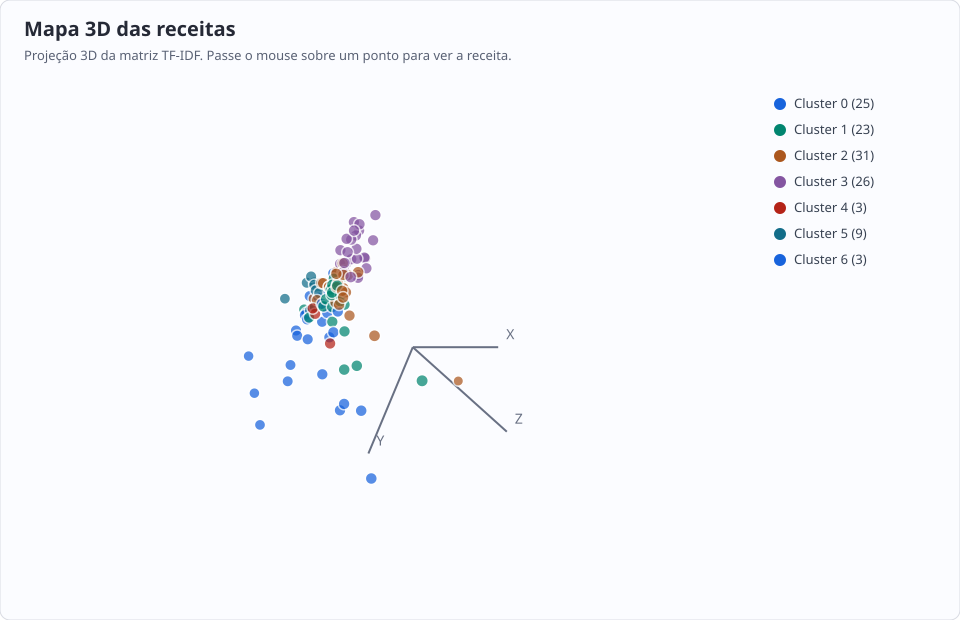

In [9]:
# O gráfico abaixo usa a projeção 3D salva na tabela document_vectors.
# A variável `analise` foi carregada na célula anterior.
import math

def renderizar_mapa_3d(analise):
    docs = (analise or {}).get("documents", [])
    width, height = 960, 620
    colors = ["#1763dc", "#00856f", "#ab571e", "#8455a1", "#b42318", "#126d89"]

    def normalizar(axis):
        values = [float(row.get(axis) or 0.0) for row in docs]
        if not values:
            return []
        low, high = min(values), max(values)
        if high == low:
            return [0.0 for _ in values]
        return [((value - low) / (high - low) - 0.5) * 2 for value in values]

    xs, ys, zs = normalizar("x"), normalizar("y"), normalizar("z")
    angle_x, angle_y = -0.55, 0.75

    def projetar(x, y, z):
        cx, sx = math.cos(angle_x), math.sin(angle_x)
        cy, sy = math.cos(angle_y), math.sin(angle_y)
        y1 = y * cx - z * sx
        z1 = y * sx + z * cx
        x2 = x * cy + z1 * sy
        z2 = -x * sy + z1 * cy
        perspective = 0.84 / (1.8 - z2 * 0.38)
        size = min(width, height) * 0.40
        return width * 0.43 + x2 * size * perspective, height * 0.56 + y1 * size * perspective, z2

    def eixo(label, end, color):
        origin = projetar(0, 0, 0)
        target = projetar(*end)
        return (
            f'<line x1="{origin[0]:.1f}" y1="{origin[1]:.1f}" x2="{target[0]:.1f}" y2="{target[1]:.1f}" '
            f'stroke="{color}" stroke-width="2" />'
            f'<text x="{target[0] + 8:.1f}" y="{target[1] - 8:.1f}" fill="{color}" '
            f'font-size="14" font-family="system-ui, sans-serif">{label}</text>'
        )

    pontos = []
    for index, row in enumerate(docs):
        px, py, depth = projetar(xs[index], ys[index], zs[index])
        pontos.append((depth, px, py, row))
    pontos.sort(key=lambda item: item[0])

    contagem_clusters = {}
    marcadores = []
    for depth, px, py, row in pontos:
        cluster = int(row.get("cluster_label") or 0)
        contagem_clusters[cluster] = contagem_clusters.get(cluster, 0) + 1
        title = escape(str(row.get("title") or row.get("recipe_id") or "Receita"))
        color = colors[cluster % len(colors)]
        terms = ", ".join(str(item.get("term")) for item in row.get("top_terms_data", [])[:6])
        tooltip = escape(f"{title}\nCluster {cluster}\nTermos: {terms or 'sem termos'}")
        radius = max(4.5, min(7.0, 5.6 + depth * 0.45))
        marcadores.append(
            f'<g class="recipe-point"><title>{tooltip}</title>'
            f'<circle cx="{px:.1f}" cy="{py:.1f}" r="{radius:.1f}" fill="{color}" '
            f'stroke="#fff" stroke-width="1.5" /></g>'
        )

    if not marcadores:
        marcadores.append('<text x="413" y="347" text-anchor="middle">Sem documentos para projetar.</text>')

    legenda = []
    for position, cluster in enumerate(sorted(contagem_clusters)):
        legend_y = 104 + position * 26
        color = colors[cluster % len(colors)]
        legenda.append(
            f'<circle cx="780" cy="{legend_y}" r="6" fill="{color}" />'
            f'<text x="794" y="{legend_y + 4}" fill="#374151" font-size="13" '
            f'font-family="system-ui, sans-serif">Cluster {cluster} ({contagem_clusters[cluster]})</text>'
        )

    return f'''
    <svg xmlns="http://www.w3.org/2000/svg" width="100%" viewBox="0 0 {width} {height}"
         style="display:block;max-width:{width}px;height:auto">
      <style>
        .recipe-point circle {{ opacity: 0.72; transition: opacity 120ms ease, stroke-width 120ms ease; }}
        .recipe-point:hover circle {{ opacity: 1; stroke: #111827; stroke-width: 2.5; }}
      </style>
      <rect width="100%" height="100%" rx="10" fill="#fbfcff" stroke="#d9dbe3" />
      <text x="24" y="36" fill="#252936" font-size="20" font-weight="700" font-family="system-ui, sans-serif">
        Mapa 3D das receitas
      </text>
      <text x="24" y="60" fill="#596174" font-size="13" font-family="system-ui, sans-serif">
        Projeção 3D da matriz TF-IDF. Passe o mouse sobre um ponto para ver a receita.
      </text>
      {eixo("X", (1.18, 0, 0), "#687083")}
      {eixo("Y", (0, 1.18, 0), "#687083")}
      {eixo("Z", (0, 0, 1.18), "#687083")}
      {''.join(marcadores)}
      {''.join(legenda)}
    </svg>
    '''

display(SVG(renderizar_mapa_3d(analise)))


## 8. Similaridade por TF-IDF


In [10]:
# Similaridade por cosseno entre vetores TF-IDF.
display(HTML("Tabela de similaridades TF-IDF já exibida no output."))


Receita,Vizinha,Rank,Similaridade
Risoto de Camarão,Estrogonofe de camarão,1,0.234
Risoto de Camarão,Camarão com requeijão,2,0.2315
Risoto de Camarão,Moqueca de camarão,3,0.2033
Risoto de Camarão,Estrogonofe de camarão,4,0.1879
Risoto de Camarão,Bobó de camarão,5,0.1849
Filé de peixe ao forno,Moqueca de peixe fácil,1,0.2554
Filé de peixe ao forno,Moqueca de peixe,2,0.2329
Filé de peixe ao forno,Moqueca capixaba - a legítima,3,0.2277
Filé de peixe ao forno,Filé de merluza com batata ao forno,4,0.1814
Filé de peixe ao forno,Filé de peixe da mamãe,5,0.1746


## 9. Etapa 7 — embeddings densos por contexto


In [11]:
connection = connect_database(DATABASE_PATH)
embeddings = latest_embedding_analysis(connection)
connection.close()
display(HTML("Tokens mais representativos dos embeddings já exibidos no output."))


Tabela HTML pronta no output do notebook.

## 10. Contextos aprendidos pelas palavras


In [12]:
# Mostra quais palavras apareceram como contexto de outras palavras.
display(HTML("Contextos aprendidos já exibidos no output."))


Termo,Contexto,Peso PPMI
0,centimetro,7.2528
0,descascada,6.0001
0,fatia,5.6434
0,5,5.1734
0,rodela,4.0339
0,1,1.0204
1,quilo,2.8121
1,2kg,2.4067
1,abaix,2.4067
1,amarelo,2.4067


## 11. Similaridade por embeddings


In [13]:
# Similaridade por cosseno entre embeddings densos das receitas.
display(HTML("Tabela de similaridades por embeddings já exibida no output."))


Receita,Vizinha,Rank,Similaridade
Risoto de Camarão,Camarão com requeijão,1,0.8963
Risoto de Camarão,Carne de panela,2,0.8953
Risoto de Camarão,Almôndegas,3,0.8895
Risoto de Camarão,Bacalhau ao Forno,4,0.88
Risoto de Camarão,Macarrão de verão Tudo Gostoso,5,0.8789
Filé de peixe ao forno,Moqueca de peixe fácil,1,0.8693
Filé de peixe ao forno,Bacalhau divino e delicioso,2,0.8569
Filé de peixe ao forno,Moqueca de peixe,3,0.8557
Filé de peixe ao forno,Filé de merluza com batata ao forno,4,0.8555
Filé de peixe ao forno,Moqueca capixaba - a legítima,5,0.8533


## 12. Aula 7 — busca semântica


In [14]:
consulta_semantica = 'carne com cebola'
connection = connect_database(DATABASE_PATH)
modelo_embeddings = load_latest_embedding_model(connection)
resultados_semanticos = semantic_search(modelo_embeddings, consulta_semantica, limit=5) if modelo_embeddings else []
connection.close()
display(HTML("Resultado da busca semântica já exibido no output."))


Receita,Similaridade,Termos reconhecidos
Carne de panela de pressão,0.5166,"['carne', 'cebola']"
Escondidinho de carne moída,0.4801,"['carne', 'cebola']"
Rocambole de carne moída maravilhoso,0.4495,"['carne', 'cebola']"
Panqueca de banana fit,0.4443,"['carne', 'cebola']"
Estrogonofe de camarão,0.4337,"['carne', 'cebola']"


## 13. Aula 7 — embedding estático e representação contextual


In [15]:
connection = connect_database(DATABASE_PATH)
modelo_embeddings = load_latest_embedding_model(connection)
exemplos_contextuais = []
if modelo_embeddings and modelo_embeddings.documents:
    documento = modelo_embeddings.documents[0]
    ocorrencias = contextualize_tokens(documento.tokens, modelo_embeddings)
    exemplos_contextuais = [
        {
            "token": item.token,
            "posição": item.position,
            "contexto": item.context,
            "dimensões": len(item.vector),
        }
        for item in ocorrencias[:8]
    ]
connection.close()
display(HTML("Ocorrências contextualizadas já exibidas no output."))


Receita,Token,Posição,Janela local,Dimensões
Risoto de Camarão,risoto,2,"descubra, receita, camarao, fazer",32
Risoto de Camarão,risoto,269,"sirva, quente, camarao",32


## 14. Aula 8 — classificação supervisionada


In [16]:
connection = connect_database(DATABASE_PATH)
classificacao = latest_text_classification(connection)
connection.close()
display(HTML("Resumo da classificação já exibido no output."))


Métrica,Valor
Execução,3
Modelo,pln-aula-8-naive-bayes-v1
Alvo,difficulty
Tipo,ordinal
Documentos,120
Treino,90
Teste,30
Classes,1
Status,insufficient_classes


## 15. Aula 8 — previsões, probabilidades e divisão treino/teste


In [17]:
previsoes = (classificacao or {}).get("predictions", [])
display(HTML("Previsões já exibidas no output."))


Receita,Conjunto,Classe real,Classe prevista,Maior probabilidade
"Almôndega ao molho de tomate - rápida, prática e gostosa",test,fácil,fácil,1
Arroz de forno à parmegiana,test,fácil,fácil,1
Batata suíça,test,fácil,fácil,1
Bolo de banana de liquidificador sem glúten e sem lactose,test,fácil,fácil,1
Bolo fácil de laranja sem glúten,test,fácil,fácil,1
Camarão com requeijão,test,fácil,fácil,1
Costela de boi na panela de pressão cozida na cebola,test,fácil,fácil,1
Costela na pressão com lingüiça,test,fácil,fácil,1
Escondidinho de carne-seca,test,fácil,fácil,1
Esfiha de carne adaptada (receita turca),test,fácil,fácil,1


## 16. Aula 8 — matriz de confusão e métricas


In [18]:
metricas = (classificacao or {}).get("metrics", [])
matriz_confusao = (classificacao or {}).get("confusion", {})
display(HTML("Métricas e matriz de confusão já exibidas no output."))


Tabela HTML pronta no output do notebook.

## 17. Aula 9 — análise linguística e extração de informação


In [19]:
connection = connect_database(DATABASE_PATH)
linguistica = latest_linguistic_analysis(connection)
connection.close()
display(HTML("Resumo da aula 9 já exibido no output."))


Métrica,Valor
Execução,3
Versão,pln-aula-9-domain-rules-v1
Documentos,120
Sentenças,780
Dependências,11241
Sentimentos,2505
Entidades,3427
Relações,2251


## 18. Aula 9 — parsing e dependências


In [20]:
dependencias = (linguistica or {}).get("dependencies", [])
display(HTML("Dependências sintáticas rasas já exibidas no output."))


Receita,Sentença,Índice,Token,Lema,Núcleo,Relação
Risoto de Camarão,0,0,espremer,espremer,6,nsubj
Risoto de Camarão,0,1,um,um,2,det
Risoto de Camarão,0,2,limao,limao,6,nsubj
Risoto de Camarão,0,3,nos,nos,4,case
Risoto de Camarão,0,4,camaroes,camarao,6,nsubj
Risoto de Camarão,0,5,e,e,6,nsubj
Risoto de Camarão,0,6,deixar,deixar,—,root
Risoto de Camarão,0,7,descansando,descansando,6,obj
Risoto de Camarão,0,8,enquanto,enquanto,6,nmod
Risoto de Camarão,0,9,voce,voce,6,nmod


## 19. Aula 9 — análise de sentimentos e aspectos


In [21]:
sentimentos = (linguistica or {}).get("sentiments", [])
display(HTML("Análises de sentimento já exibidas no output."))


Receita,Campo,Posição,Polaridade,Escore,Subjetividade,Evidências,Aspectos
Risoto de Camarão,description,0,neutro,0,0,—,—
Risoto de Camarão,ingredient,1,neutro,0,0,—,—
Risoto de Camarão,ingredient,2,neutro,0,0,—,—
Risoto de Camarão,ingredient,3,negativo,-0.5333,0.6667,seco,textura
Risoto de Camarão,ingredient,4,neutro,0,0,—,—
Risoto de Camarão,ingredient,5,neutro,0,0,—,—
Risoto de Camarão,ingredient,6,neutro,0,0,—,—
Risoto de Camarão,ingredient,7,neutro,0,0,—,—
Risoto de Camarão,ingredient,8,neutro,0,0,—,—
Risoto de Camarão,ingredient,9,neutro,0,0,—,—


## 20. Aula 9 — entidades nomeadas de domínio


In [22]:
entidades = (linguistica or {}).get("entities", [])
display(HTML("Entidades de domínio já exibidas no output."))


Receita,Campo,Posição,Entidade,Tipo,Valor normalizado,BIO,Método
Risoto de Camarão,description,0,60,QUANTITY,60,B-QUANTITY,domain_regex
Risoto de Camarão,description,0,60 minutos,DURATION,60 minutos,B-DURATION,domain_regex
Risoto de Camarão,description,0,1,QUANTITY,1,B-QUANTITY,domain_regex
Risoto de Camarão,ingredient,1,500,QUANTITY,500,B-QUANTITY,domain_regex
Risoto de Camarão,ingredient,1,500 g de camarão médio,INGREDIENT,camarao medio,B-INGREDIENT,structured_field
Risoto de Camarão,ingredient,1,g,UNIT,g,B-UNIT,domain_regex
Risoto de Camarão,ingredient,2,1,QUANTITY,1,B-QUANTITY,domain_regex
Risoto de Camarão,ingredient,2,1 1/2 xícara de arroz carnaroli ou arbóreo,INGREDIENT,arroz carnaroli ou arboreo,B-INGREDIENT,structured_field
Risoto de Camarão,ingredient,2,1/2,QUANTITY,1/2,B-QUANTITY,domain_regex
Risoto de Camarão,ingredient,2,xícara,UNIT,xicara,B-UNIT,domain_regex


## 21. Aula 9 — extração de relações


In [23]:
relacoes = (linguistica or {}).get("relations", [])
display(HTML("Relações semânticas já exibidas no output."))


Receita,Sujeito,Relação,Objeto,Confiança,Método
Risoto de Camarão,Risoto de Camarão,tem_ingrediente,camarao medio,1,structured_field
Risoto de Camarão,Risoto de Camarão,tem_ingrediente,arroz carnaroli ou arboreo,1,structured_field
Risoto de Camarão,Risoto de Camarão,tem_ingrediente,vinho branco seco,1,structured_field
Risoto de Camarão,Risoto de Camarão,tem_ingrediente,champignon (opcional) cortado em laminas,1,structured_field
Risoto de Camarão,Risoto de Camarão,tem_ingrediente,"tomates (italiano) grandes, maduros e",1,structured_field
Risoto de Camarão,Risoto de Camarão,tem_ingrediente,cebolas pequenas raladas,1,structured_field
Risoto de Camarão,Risoto de Camarão,tem_ingrediente,alho amassados,1,structured_field
Risoto de Camarão,Risoto de Camarão,tem_ingrediente,talo salsao picadinho,1,structured_field
Risoto de Camarão,Risoto de Camarão,tem_ingrediente,caldo camarao (ou peixe ou legumes),1,structured_field
Risoto de Camarão,Risoto de Camarão,tem_ingrediente,creme leite,1,structured_field
